# 선형회귀 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week02/linear_regression/lab/linear_regression.ipynb)

직선 $h = w_0 + w_1 x$, 비용 $J$ (오차 제곱의 평균), 경사하강법. 슬라이드의 숫자를 직접 재현하고 실제 자동차 데이터에 써 본다.

- **파트 1**: 경사하강법 직접 구현 → 7시간 75.3점 재현 · 학습률 바꿔 발산 보기
- **파트 2**: 자동차 398대: 마력 → 연비, 직선 vs $x^2$ vs $\log x$
- **파트 3**: 차수를 올리며 학습 / 시험 오차 비교 (과적합)

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Same example as the slides: study hours and scores of 30 students
x = np.array([6.4, 9.0, 7.9, 2.6, 3.4, 8.8, 0.6, 8.3, 8.1, 4.9,
              3.4, 3.1, 2.9, 4.7, 5.3, 5.8, 10.0, 8.0, 6.4, 9.9,
              2.5, 2.0, 6.3, 0.9, 0.8, 5.4, 4.9, 9.2, 6.5, 5.4])      # study hours
y = np.array([65, 83, 74, 49, 62, 80, 43, 86, 77, 64,
              57, 56, 48, 64, 73, 61, 94, 81, 69, 99,
              57, 44, 72, 47, 43, 70, 64, 89, 80, 64])      # exam score
plt.scatter(x, y); plt.xlabel("study hours"); plt.ylabel("score"); plt.show()

**예상 결과**

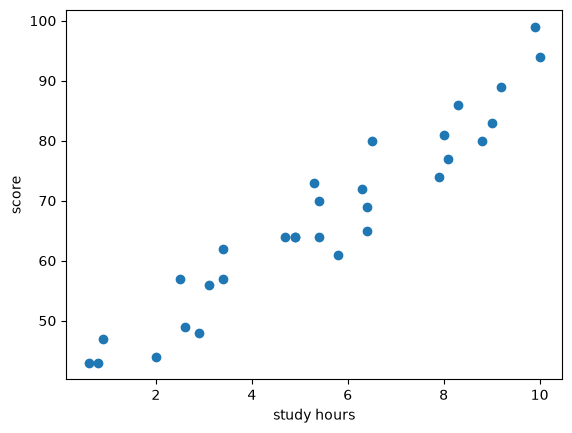

## 파트 1. 경사하강법 직접 구현

$$J = \frac{1}{2m}\sum (h - y)^2, \qquad \frac{\partial J}{\partial w_0} = \frac{1}{m}\sum (h - y), \qquad \frac{\partial J}{\partial w_1} = \frac{1}{m}\sum (h - y)\,x$$

In [ ]:
def cost(w0, w1, x, y):
    return np.mean((w0 + w1 * x - y) ** 2) / 2

def gradient(w0, w1, x, y):
    err = w0 + w1 * x - y                                # error h - y
    g0 = None               # TODO: ∂J/∂w0
    g1 = None               # TODO: ∂J/∂w1
    return g0, g1

def gradient_descent(x, y, alpha, steps, w0=0.0, w1=0.0):
    history = []
    for _ in range(steps):
        g0, g1 = gradient(w0, w1, x, y)
        w0, w1 = None, None     # TODO: one step
        history.append(cost(w0, w1, x, y))
    return w0, w1, history

w0, w1, hist = gradient_descent(x, y, alpha=0.02, steps=5000)
print(f"w0 = {w0:.2f}, w1 = {w1:.2f}  ->  7 hours gives {w0 + 7 * w1:.1f} points")
m_ = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"sklearn: w0 = {m_.intercept_:.2f}, w1 = {m_.coef_[0]:.2f}")
plt.plot(hist); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("cost J"); plt.show()

**예상 결과**

```
w0 = 38.58, w1 = 5.25  ->  7 hours gives 75.3 points
sklearn: w0 = 38.58, w1 = 5.25
```

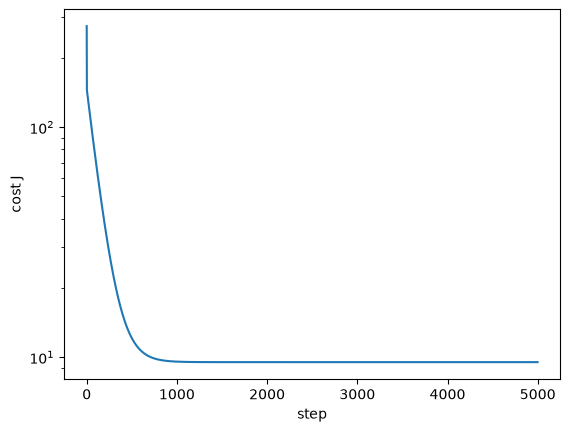

In [ ]:
# Try larger learning rates: 0.05 and 0.06
for alpha in [0.05, 0.06]:
    _, _, h = gradient_descent(x, y, alpha, steps=30)
    print(f"alpha={alpha}: first J={h[0]:.1f}  after 30 steps J={h[-1]:.3g}")

**예상 결과**

```
alpha=0.05: first J=1944.5  after 30 steps J=89.8
alpha=0.06: first J=3783.8  after 30 steps J=6.03e+09
```

**관찰**: 0.06 은 발산한다. 슬라이드의 오른쪽 그림처럼 바닥을 건너뛰며 매번 더 높이 튄다.

$R^2$ 와 RMSE 도 확인하자 (슬라이드: RMSE 4.36, $R^2$ 0.916).

In [ ]:
pred = w0 + w1 * x
rmse = None             # TODO: RMSE (no 1/2)
print(f"RMSE = {rmse:.2f},  R² = {r2_score(y, pred):.3f}")

**예상 결과**

```
RMSE = 4.36,  R² = 0.916
```

## 파트 2. 실제 자동차 데이터: 마력 → 연비

Auto MPG: 1970~82년 자동차 398대. 마력(horsepower) 이 클수록 연비(mpg, 갤런당 마일) 는 떨어지는데, 직선일까? 처음 실행하면 CSV 를 내려받는다.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/mpg.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/mpg.csv")
df = pd.read_csv("data/mpg.csv").dropna(subset=["horsepower"])
hp, mpg = df["horsepower"].to_numpy(float), df["mpg"].to_numpy(float)
print(len(df), "cars");  print(df[["name", "horsepower", "mpg"]].head())
plt.scatter(hp, mpg, s=12); plt.xlabel("horsepower"); plt.ylabel("mpg"); plt.show()

**예상 결과**

```
392 cars
                        name  horsepower   mpg
0  chevrolet chevelle malibu       130.0  18.0
1          buick skylark 320       165.0  15.0
2         plymouth satellite       150.0  18.0
3              amc rebel sst       150.0  16.0
4                ford torino       140.0  17.0
```

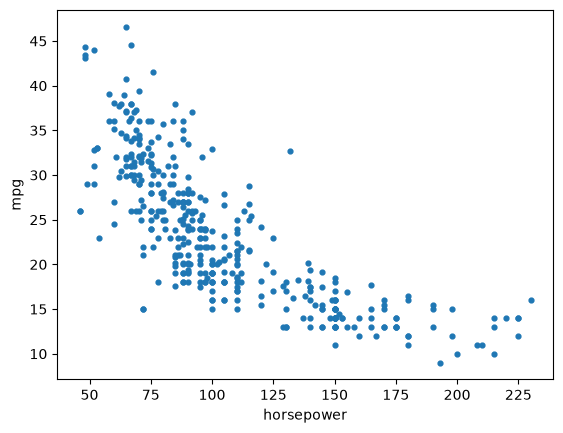

In [ ]:
features = {
    "x":        hp.reshape(-1, 1),
    "x, x²":    np.c_[hp, hp ** 2],
    "log x":    None,         # TODO: one column, log-transformed
}
hs = np.linspace(hp.min(), hp.max(), 200)
plt.scatter(hp, mpg, s=10, color="lightgray")
for name, F in features.items():
    model = LinearRegression().fit(F, mpg)
    print(f"{name:8s}: R² = {r2_score(mpg, model.predict(F)):.3f}")
    Fs = {"x": hs.reshape(-1, 1), "x, x²": np.c_[hs, hs ** 2], "log x": np.log(hs).reshape(-1, 1)}[name]
    plt.plot(hs, model.predict(Fs), lw=2, label=name)
plt.legend(); plt.xlabel("horsepower"); plt.ylabel("mpg"); plt.show()

**예상 결과**

```
x       : R² = 0.606
x, x²   : R² = 0.688
log x   : R² = 0.668
```

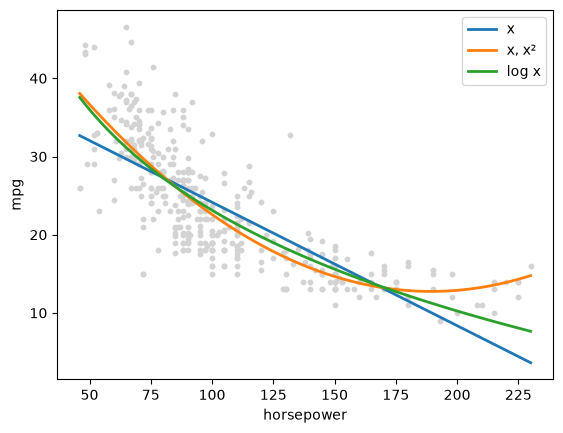

## 파트 3. 차수를 계속 올리면? (과적합)

자동차 **25대만** 학습에 쓰고, 나머지 367대로 시험한다. 데이터가 적을 때 차수를 올리면 어떻게 될까?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

h_tr, h_te, m_tr, m_te = train_test_split(hp.reshape(-1, 1), mpg, train_size=25, random_state=0)
degrees = [1, 2, 3, 4, 6, 8, 10]
tr_err, te_err = [], []
for k in degrees:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(k), LinearRegression()).fit(h_tr, m_tr)
    tr_err.append(np.sqrt(mean_squared_error(m_tr, model.predict(h_tr))))
    te_err.append(None)  # TODO: test RMSE
    print(f"degree {k:2d}: train RMSE {tr_err[-1]:6.2f}   test RMSE {te_err[-1]:8.2f}")
plt.plot(degrees, tr_err, "o-", label="train"); plt.plot(degrees, te_err, "s-", label="test")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("RMSE (mpg)"); plt.legend(); plt.show()

**예상 결과**

```
degree  1: train RMSE   5.20   test RMSE     4.93
degree  2: train RMSE   3.85   test RMSE     4.69
degree  3: train RMSE   3.47   test RMSE     4.89
degree  4: train RMSE   3.47   test RMSE     4.88
degree  6: train RMSE   3.33   test RMSE     6.53
degree  8: train RMSE   1.90   test RMSE   132.51
degree 10: train RMSE   1.73   test RMSE   364.55
```

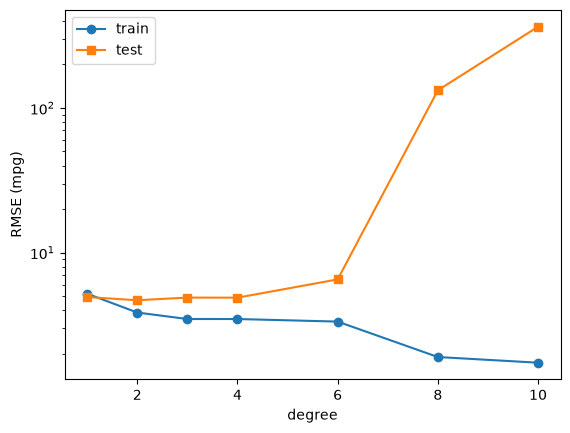

**확인 질문**
1. 파트 1 에서 학습률 0.06 이 발산하는 이유를 슬라이드의 그림으로 설명해 보자.
2. 파트 2 에서 가장 좋은 특징은? 그 모델도 '선형'회귀인 이유는?
3. 파트 3 에서 알맞은 차수는 몇이라고 생각하나? 학습 오차만 보고 고르면 몇 차를 고르게 될까? `train_size` 를 200 으로 늘리면 어떻게 달라질까?
4. (도전) `df` 의 `weight`(무게) 를 특징으로 추가하면 $R^2$ 이 얼마나 오를까?

데이터 출처: Auto MPG, UCI Machine Learning Repository (Quinlan, 1993), seaborn-data 사본.